# DWD-Wetterdaten: mehrere Berliner Stationen

Dieses Notebook dokumentiert Tagesdaten von sechs DWD-Stationen im Bundesland Berlin ab 2020. Die zusammengeführte CSV enthält eine Zeile pro Station und Messtag. Hier prüfen wir zunächst nur Quelle, Stationsabdeckung und Verfügbarkeit der gewünschten Messgrößen.

## Datenquelle und CSV

Die Daten stammen aus den täglichen Klimabeobachtungen (KL) des [DWD Climate Data Center](https://opendata.dwd.de/climate_environment/CDC/observations_germany/climate/daily/kl/). Historische und aktuelle DWD-Dateien wurden je Station anhand des Datums zusammengeführt; bei Überschneidungen hat die aktuelle Datei Vorrang.

Die Datei `dwd_berlin_stationen_2020_bis_heute.csv` enthält 10.118 Zeilen vom 01.01.2020 bis zum letzten verfügbaren Messtag 01.11.2026. Sie hat die Spalten `station_id`, `station_name`, `datum`, `temp_min_c`, `temp_max_c`, `temp_durch_c`, `niederschlagsmenge_mm` und `sonnenstunden`. DWD-Fehlwertmarker (`-999`) sind als leere CSV-Felder gespeichert; leer bedeutet fehlender Messwert, nicht null.

## Enthaltene Stationen und Messwertabdeckung

| ID | Station | Datenzeitraum | Temperatur min/max/Mittel | Niederschlag | Sonnenstunden |
| ---: | --- | --- | ---: | ---: | ---: |
| 00400 | Berlin-Buch | 2020-01-01 bis 2026-11-01 | 2.497/2.497 | 2.497/2.497 | 0/2.497 |
| 00403 | Berlin-Dahlem (FU) | 2020-01-01 bis 2026-11-01 | 2.481/2.483 | 2.482/2.483 | 2.481/2.483 |
| 00410 | Berlin-Kaniswall | 2020-01-01 bis 2020-06-15 | 105/167 | 107/167 | 0/167 |
| 00420 | Berlin-Marzahn | 2020-01-01 bis 2026-11-01 | 1.977/1.984 | 1.977/1.984 | 0/1.984 |
| 00430 | Berlin-Tegel | 2020-01-01 bis 2021-05-04 | 490/490 | 490/490 | 490/490 |
| 00433 | Berlin-Tempelhof | 2020-01-01 bis 2026-11-01 | 2.497/2.497 | 2.486/2.497 | 984/2.497 |

Die Werte in der Abdeckungstabelle sind gültige Tage/Zeilen der jeweiligen Station. Kaniswall und Tegel wurden im Zeitraum eingestellt. Sonnenstunden fehlen in Buch, Kaniswall und Marzahn vollständig; in Tempelhof sind sie nur bis 10.09.2022 vorhanden. Dahlem hat zwei Messtage ohne Sonnenstundenwerte. Der Flughafen Berlin Brandenburg (00427) liegt im Bundesland Brandenburg und ist deshalb nicht als Berliner Station enthalten.

## CSV einlesen und Abdeckung nachprüfen

Die folgende Zelle verwendet nur die Python-Standardbibliothek und zählt pro Station die vorhandenen Werte.

In [1]:
import csv
from collections import defaultdict
from pathlib import Path

csv_pfad = Path("dwd_berlin_stationen_2020_bis_heute.csv")
with csv_pfad.open(encoding="utf-8", newline="") as datei:
    daten = list(csv.DictReader(datei))

messspalten = [
    "temp_min_c",
    "temp_max_c",
    "temp_durch_c",
    "niederschlagsmenge_mm",
    "sonnenstunden",
]
stationen = defaultdict(list)
for zeile in daten:
    stationen[zeile["station_id"]].append(zeile)

print(f"Zeilen gesamt: {len(daten)} | Stationen: {len(stationen)}")
for station_id, zeilen in sorted(stationen.items()):
    name = zeilen[0]["station_name"]
    zeilen.sort(key=lambda zeile: zeile["datum"])
    print(f"\n{station_id} {name}: {zeilen[0]['datum']} bis {zeilen[-1]['datum']} ({len(zeilen)} Zeilen)")
    for spalte in messspalten:
        gueltig = sum(bool(zeile[spalte].strip()) for zeile in zeilen)
        print(f"  {spalte}: {gueltig}/{len(zeilen)} gültig")

Zeilen gesamt: 10118 | Stationen: 6

00400 Berlin-Buch: 2020-01-01 bis 2026-11-01 (2497 Zeilen)
  temp_min_c: 2497/2497 gültig
  temp_max_c: 2497/2497 gültig
  temp_durch_c: 2497/2497 gültig
  niederschlagsmenge_mm: 2497/2497 gültig
  sonnenstunden: 0/2497 gültig

00403 Berlin-Dahlem (FU): 2020-01-01 bis 2026-11-01 (2483 Zeilen)
  temp_min_c: 2481/2483 gültig
  temp_max_c: 2481/2483 gültig
  temp_durch_c: 2481/2483 gültig
  niederschlagsmenge_mm: 2482/2483 gültig
  sonnenstunden: 2481/2483 gültig

00410 Berlin-Kaniswall: 2020-01-01 bis 2020-06-15 (167 Zeilen)
  temp_min_c: 105/167 gültig
  temp_max_c: 105/167 gültig
  temp_durch_c: 105/167 gültig
  niederschlagsmenge_mm: 107/167 gültig
  sonnenstunden: 0/167 gültig

00420 Berlin-Marzahn: 2020-01-01 bis 2026-11-01 (1984 Zeilen)
  temp_min_c: 1977/1984 gültig
  temp_max_c: 1977/1984 gültig
  temp_durch_c: 1977/1984 gültig
  niederschlagsmenge_mm: 1977/1984 gültig
  sonnenstunden: 0/1984 gültig

00430 Berlin-Tegel: 2020-01-01 bis 2021-05-

## Durchschnittstemperatur im Jahresverlauf: Berlin-Dahlem

Die Linien zeigen die DWD-Tagesmitteltemperatur (Spalte `temp_durch_c`) der Station **Berlin-Dahlem (FU), ID 00403**. Alle Jahre liegen auf derselben Monats-/Tagesachse, damit sich die saisonalen Verläufe vergleichen lassen. Der 29. Februar wird für alle Jahre ausgelassen; fehlende Messwerte bleiben als Lücken sichtbar. **2026 ist ein unvollständiges Jahr** (Daten bis 01.11.2026), und für 2025 liegen in Dahlem 349 gültige Tagesmittelwerte vor.

Falls `matplotlib` noch nicht installiert ist, führe in einer Codezelle `%pip install matplotlib` aus.

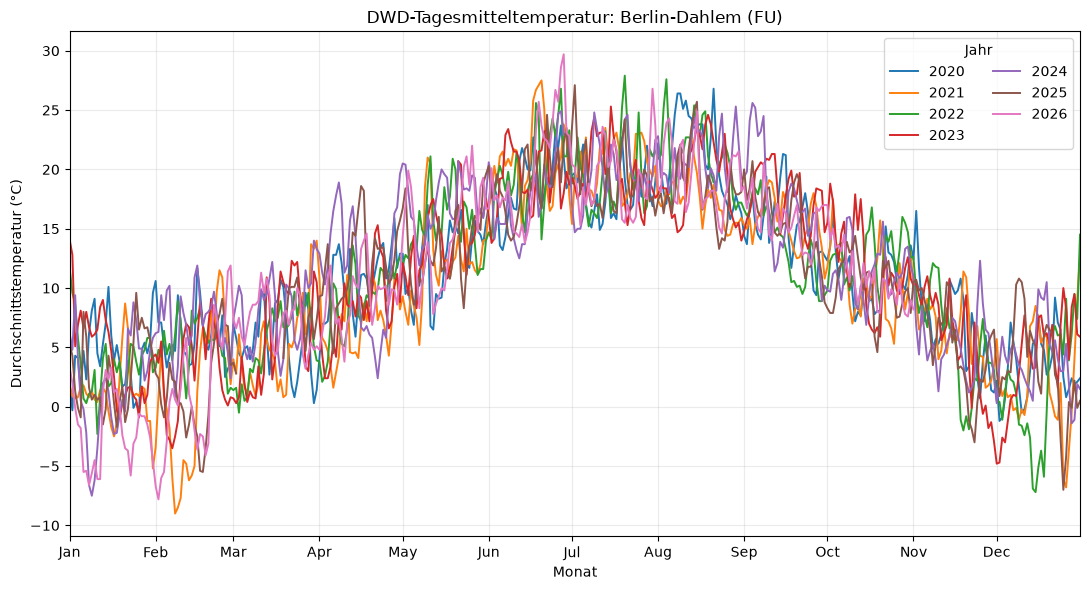

Gültige Tagesmittelwerte je Jahr:
2020: 365 Tage
2021: 365 Tage
2022: 365 Tage
2023: 365 Tage
2024: 365 Tage
2025: 349 Tage
2026: 305 Tage


In [2]:
from collections import defaultdict
from datetime import datetime, timedelta
import calendar

import matplotlib.dates as mdates
import matplotlib.pyplot as plt

# DWD-Mitteltemperaturen der Station Berlin-Dahlem (FU), ID 00403
csv_pfad = Path("dwd_berlin_stationen_2020_bis_heute.csv")
temperaturen_nach_jahr = defaultdict(dict)
with csv_pfad.open(encoding="utf-8", newline="") as datei:
    for zeile in csv.DictReader(datei):
        if zeile["station_id"] != "00403" or not zeile["temp_durch_c"].strip():
            continue
        datum = datetime.strptime(zeile["datum"], "%Y-%m-%d")
        if datum.month == 2 and datum.day == 29:
            continue
        tag_im_jahr = datum.timetuple().tm_yday
        if calendar.isleap(datum.year) and datum.month > 2:
            tag_im_jahr -= 1
        temperaturen_nach_jahr[datum.year][tag_im_jahr - 1] = float(
            zeile["temp_durch_c"]
        )

kalender = [datetime(2001, 1, 1) + timedelta(days=tag) for tag in range(365)]
fig, ax = plt.subplots(figsize=(11, 6))
farben = plt.get_cmap("tab10")
for index, (jahr, werte) in enumerate(sorted(temperaturen_nach_jahr.items())):
    temperaturwerte = [werte.get(tag, float("nan")) for tag in range(365)]
    ax.plot(
        kalender,
        temperaturwerte,
        color=farben(index % farben.N),
        linewidth=1.4,
        label=str(jahr),
    )

ax.set_title("DWD-Tagesmitteltemperatur: Berlin-Dahlem (FU)")
ax.set_xlabel("Monat")
ax.set_ylabel("Durchschnittstemperatur (°C)")
ax.set_xlim(kalender[0], kalender[-1])
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.grid(alpha=0.25)
ax.legend(title="Jahr", ncol=2)
fig.tight_layout()
plt.show()

print("Gültige Tagesmittelwerte je Jahr:")
for jahr, werte in sorted(temperaturen_nach_jahr.items()):
    print(f"{jahr}: {len(werte)} Tage")

Tägliche Temperaturen innerhalb der Saison (°C)
Winter: 6 Saisons, 541 Tage, Mittel=2.7, Standardabweichung=4.3, P10–P90=-2.6 bis 8.0
Sommer: 6 Saisons, 552 Tage, Mittel=19.5, Standardabweichung=3.0, P10–P90=15.5 bis 23.4


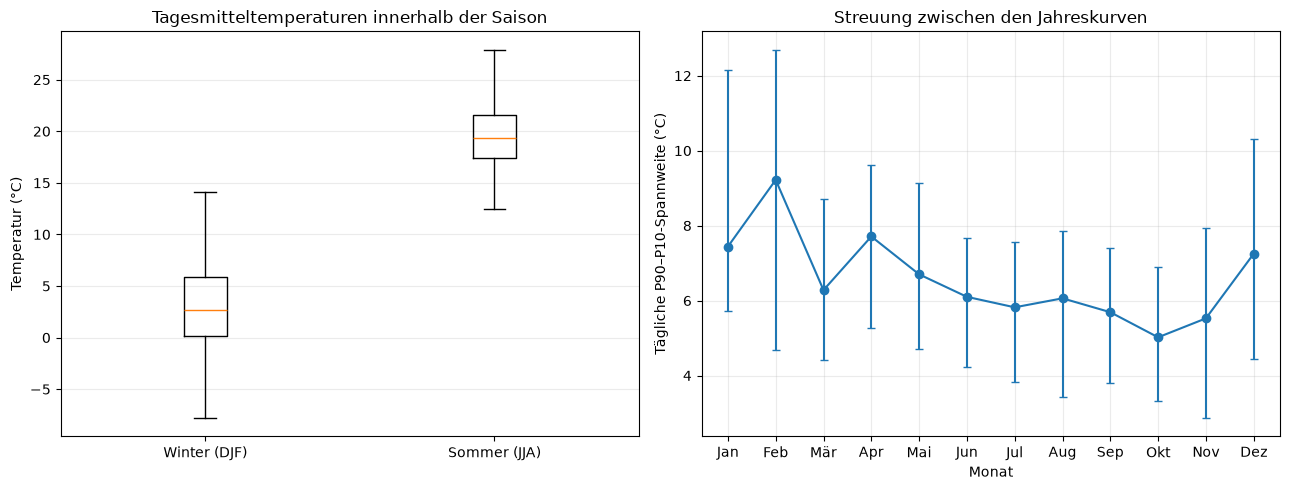

In [3]:
from collections import defaultdict
from datetime import datetime
import statistics

# Tagesmitteltemperaturen aus Berlin-Dahlem laden und saisonal zuordnen
saisonwerte = defaultdict(list)

with csv_pfad.open(encoding="utf-8", newline="") as datei:
    for zeile in csv.DictReader(datei):
        if zeile["station_id"] != "00403" or not zeile["temp_durch_c"].strip():
            continue

        datum = datetime.strptime(zeile["datum"], "%Y-%m-%d")
        temperatur = float(zeile["temp_durch_c"])

        if datum.month in (12, 1, 2):
            winterjahr = datum.year + (datum.month == 12)
            saisonwerte[("Winter", winterjahr)].append(temperatur)
        elif datum.month in (6, 7, 8):
            saisonwerte[("Sommer", datum.year)].append(temperatur)


def quantil(werte, anteil):
    sortiert = sorted(werte)
    position = (len(sortiert) - 1) * anteil
    unten = int(position)
    oben = min(unten + 1, len(sortiert) - 1)
    gewicht = position - unten
    return sortiert[unten] * (1 - gewicht) + sortiert[oben] * gewicht


# Nur dieselben Saisonjahre vergleichen; unvollständige Saisons aussortieren.
saisonjahre = range(2021, 2027)
winterwerte, sommerwerte = [], []
verwendete_saisons = {"Winter": [], "Sommer": []}

for jahr in saisonjahre:
    erwarteter_winter = (
        31
        + (29 if calendar.isleap(jahr) else 28)
        + calendar.monthrange(jahr, 2)[1]
    )
    erwarteter_sommer = sum(calendar.monthrange(jahr, monat)[1] for monat in (6, 7, 8))

    winter = saisonwerte[("Winter", jahr)]
    sommer = saisonwerte[("Sommer", jahr)]

    if len(winter) >= 0.8 * erwarteter_winter:
        winterwerte.extend(winter)
        verwendete_saisons["Winter"].append(jahr)

    if len(sommer) >= 0.8 * erwarteter_sommer:
        sommerwerte.extend(sommer)
        verwendete_saisons["Sommer"].append(jahr)

print("Tägliche Temperaturen innerhalb der Saison (°C)")
for name, werte in (("Winter", winterwerte), ("Sommer", sommerwerte)):
    print(
        f"{name}: {len(verwendete_saisons[name])} Saisons, "
        f"{len(werte)} Tage, Mittel={statistics.mean(werte):.1f}, "
        f"Standardabweichung={statistics.pstdev(werte):.1f}, "
        f"P10–P90={quantil(werte, 0.1):.1f} bis {quantil(werte, 0.9):.1f}"
    )

# Interannuelle Spannweite je Kalendertag, danach monatlicher Median.
spannweite_pro_monat = defaultdict(list)
for tag in range(365):
    tageswerte = [
        werte[tag]
        for werte in temperaturen_nach_jahr.values()
        if tag in werte
    ]
    if len(tageswerte) < 4:
        continue

    monat = kalender[tag].month
    spannweite_pro_monat[monat].append(
        quantil(tageswerte, 0.9) - quantil(tageswerte, 0.1)
    )

monate = sorted(spannweite_pro_monat)
mediane = [statistics.median(spannweite_pro_monat[m]) for m in monate]
untere = [quantil(spannweite_pro_monat[m], 0.1) for m in monate]
obere = [quantil(spannweite_pro_monat[m], 0.9) for m in monate]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5))

ax1.boxplot(
    [winterwerte, sommerwerte],
    tick_labels=["Winter (DJF)", "Sommer (JJA)"],
    showfliers=False,
)
ax1.set_title("Tagesmitteltemperaturen innerhalb der Saison")
ax1.set_ylabel("Temperatur (°C)")
ax1.grid(axis="y", alpha=0.25)

ax2.errorbar(
    monate,
    mediane,
    yerr=[
        [median - low for median, low in zip(mediane, untere)],
        [high - median for median, high in zip(mediane, obere)],
    ],
    fmt="o-",
    capsize=3,
)
ax2.set_xticks(range(1, 13))
ax2.set_xticklabels(["Jan", "Feb", "Mär", "Apr", "Mai", "Jun",
                     "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"])
ax2.set_title("Streuung zwischen den Jahreskurven")
ax2.set_ylabel("Tägliche P90–P10-Spannweite (°C)")
ax2.set_xlabel("Monat")
ax2.grid(alpha=0.25)

fig.tight_layout()
plt.show()

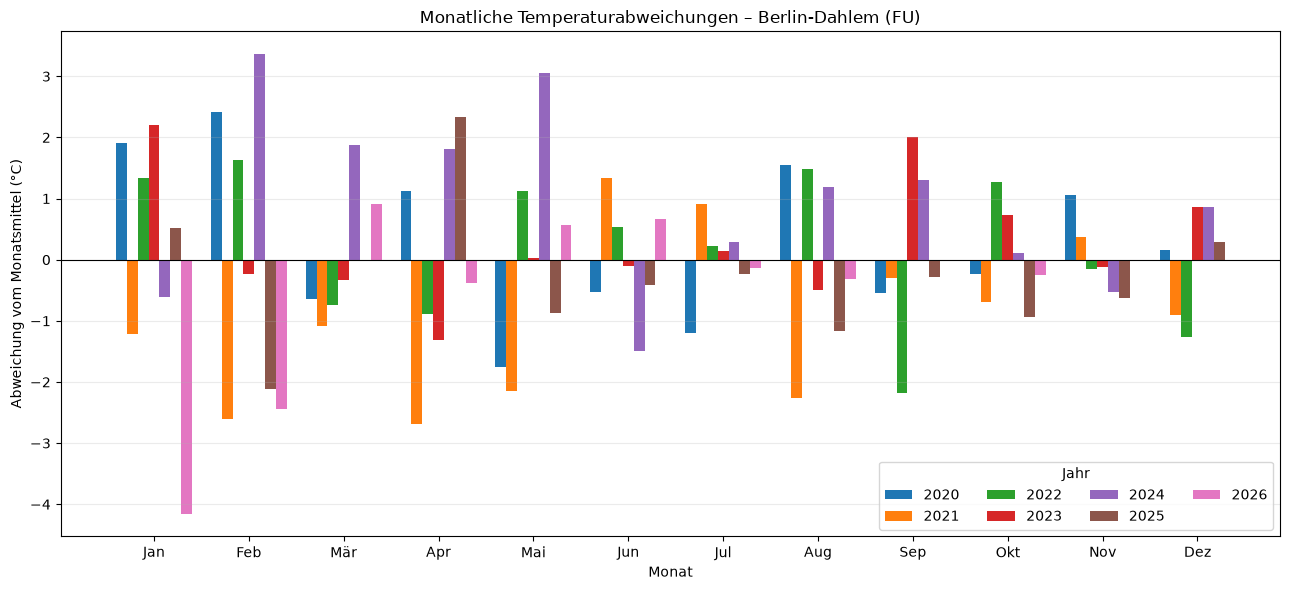

In [4]:
# Monatliche Temperaturabweichungen für Berlin-Dahlem (00403)
monatswerte_abw = defaultdict(list)

with csv_pfad.open(encoding="utf-8", newline="") as datei:
    for zeile in csv.DictReader(datei):
        if zeile["station_id"] != "00403" or not zeile["temp_durch_c"].strip():
            continue

        datum = datetime.strptime(zeile["datum"], "%Y-%m-%d")
        monatswerte_abw[(datum.year, datum.month)].append(
            float(zeile["temp_durch_c"])
        )

# Nur ausreichend vollständige Monate berücksichtigen
monatsmittel_abw = {}
for (jahr, monat), werte in monatswerte_abw.items():
    erwartete_tage = calendar.monthrange(jahr, monat)[1]
    if len(werte) >= 0.8 * erwartete_tage:
        monatsmittel_abw[(jahr, monat)] = statistics.mean(werte)

# Referenz: mittleres Monatsmittel über alle berücksichtigten Jahre
referenz_monat_abw = {
    monat: statistics.mean(
        mittel
        for (jahr, m), mittel in monatsmittel_abw.items()
        if m == monat
    )
    for monat in range(1, 13)
    if any(m == monat for _, m in monatsmittel_abw)
}

jahre_abw = sorted({jahr for jahr, _ in monatsmittel_abw})
monate_abw = list(range(1, 13))
monat_namen_abw = ["Jan", "Feb", "Mär", "Apr", "Mai", "Jun",
                   "Jul", "Aug", "Sep", "Okt", "Nov", "Dez"]

fig, ax = plt.subplots(figsize=(13, 6))
balkenbreite = 0.8 / len(jahre_abw)

for index, jahr in enumerate(jahre_abw):
    positionen = [
        monat + (index - (len(jahre_abw) - 1) / 2) * balkenbreite
        for monat in monate_abw
    ]
    abweichungen = [
        monatsmittel_abw[(jahr, monat)] - referenz_monat_abw[monat]
        if (jahr, monat) in monatsmittel_abw and monat in referenz_monat_abw
        else float("nan")
        for monat in monate_abw
    ]
    ax.bar(positionen, abweichungen, width=balkenbreite, label=str(jahr))

ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(monate_abw)
ax.set_xticklabels(monat_namen_abw)
ax.set_xlabel("Monat")
ax.set_ylabel("Abweichung vom Monatsmittel (°C)")
ax.set_title("Monatliche Temperaturabweichungen – Berlin-Dahlem (FU)")
ax.grid(axis="y", alpha=0.25)
ax.legend(title="Jahr", ncol=4)
fig.tight_layout()
plt.show()

Mittlere tägliche P90–P10-Spannweite: 6.6 °C (365 Kalendertage)


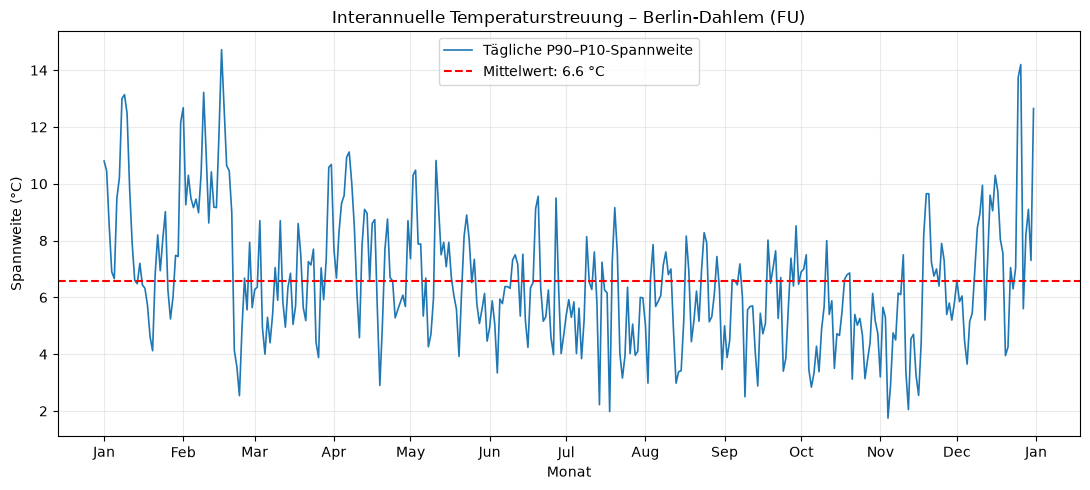

In [5]:
# Interannuelle Streuung je Kalendertag: P90 minus P10
streuung_pro_tag = []

for tag in range(365):
    tageswerte = [
        werte[tag]
        for werte in temperaturen_nach_jahr.values()
        if tag in werte
    ]
    if len(tageswerte) >= 4:
        streuung_pro_tag.append(quantil(tageswerte, 0.9) - quantil(tageswerte, 0.1))
    else:
        streuung_pro_tag.append(float("nan"))

gueltige_streuungen = [wert for wert in streuung_pro_tag if wert == wert]
mittlere_streuung = sum(gueltige_streuungen) / len(gueltige_streuungen)

print(
    f"Mittlere tägliche P90–P10-Spannweite: "
    f"{mittlere_streuung:.1f} °C "
    f"({len(gueltige_streuungen)} Kalendertage)"
)

fig, ax = plt.subplots(figsize=(11, 5))
ax.plot(kalender, streuung_pro_tag, linewidth=1.2, label="Tägliche P90–P10-Spannweite")
ax.axhline(
    mittlere_streuung,
    color="red",
    linestyle="--",
    label=f"Mittelwert: {mittlere_streuung:.1f} °C",
)
ax.set_title("Interannuelle Temperaturstreuung – Berlin-Dahlem (FU)")
ax.set_xlabel("Monat")
ax.set_ylabel("Spannweite (°C)")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

## Typischer Workflow einer Datenanalyse

1. **Fragestellung festlegen:** Was soll beantwortet werden? Beispiel: Wie unterscheiden sich die saisonalen Durchschnittstemperaturen in Berlin-Dahlem zwischen den Jahren?
2. **Daten beschaffen:** Eine passende Quelle und Station auswählen. Hier: DWD-Tageswerte, Station Berlin-Dahlem (00403), aus der CSV.
3. **Daten verstehen und prüfen:** Spalten, Einheiten, Zeitraum, Stationskennung und fehlende Werte kontrollieren. Leere Felder sind fehlende Messungen, keine Nullwerte.
4. **Daten vorbereiten:** Datumswerte und Messwerte in geeignete Formate umwandeln, die gewünschte Station und den Zeitraum filtern und unvollständige Zeiträume kennzeichnen.
5. **Daten untersuchen:** Kennzahlen, Gruppen oder Abweichungen berechnen, die zur Fragestellung passen.
6. **Ergebnisse visualisieren:** Eine geeignete Grafik wählen, zum Beispiel die überlagerten Jahreslinien für den saisonalen Temperaturverlauf.
7. **Ergebnisse interpretieren:** Muster und Unterschiede beschreiben und Einschränkungen berücksichtigen, etwa fehlende Messwerte oder das unvollständige Jahr 2026.
8. **Ergebnis dokumentieren:** Datenquelle, Station, Zeitraum, Bereinigungsschritte und Code festhalten, damit die Analyse nachvollziehbar und wiederholbar bleibt.

## Prognose der Tagesdurchschnittstemperatur

Wir bauen ein einfaches überwacht lernendes Modell für die DWD-Station **Berlin-Dahlem (FU, 00403)**. Für jeden Zieltag erhält das Modell sechs Eingaben: die Tagesmitteltemperaturen der fünf vorherigen Tage (`temp_t_minus_5` bis `temp_t_minus_1`) und den Kalendertag des Zieltags als Zahl von 1 bis 365 (`tag_im_jahr`). Das Ziel ist die gemessene Tagesmitteltemperatur des Zieltags (`temp_ziel`).

Das ist ein Lernbeispiel auf Basis historischer Wetterdaten, keine amtliche Wettervorhersage. Es verwendet keine aktuellen Wetterkarten oder Vorhersagemodelle.

Falls scikit-learn noch fehlt, installiere es in einer Notebook-Codezelle mit:

```python
%pip install scikit-learn
```

### 1. Trainingsbeispiele erstellen

Eine tägliche Zeitreihe wird in überwachte Trainingsbeispiele umgewandelt: Eine Tabellenzeile enthält die fünf aufeinanderfolgenden Messwerte vor dem Zieltag und dessen Kalendertag; die Zielspalte enthält die tatsächlich gemessene Temperatur dieses Zieltags. So lernt das Modell, aus bekannten Eingaben einen bekannten Zielwert vorherzusagen.

Fehlende Messtage werden nicht übersprungen und dadurch fälschlich als aufeinanderfolgende Tage behandelt: Wir setzen die Reihe zuerst auf einen vollständigen Tageskalender und verwenden nur Fenster, in denen alle fünf Eingabewerte und der Zielwert vorhanden sind. Der 29. Februar wird als Zieltag ausgelassen, damit `tag_im_jahr` immer zwischen 1 und 365 liegt.

In [6]:
import calendar
from pathlib import Path

import numpy as np
import pandas as pd

csv_pfad = Path("dwd_berlin_stationen_2020_bis_heute.csv")
dahlem = pd.read_csv(csv_pfad, dtype={"station_id": str})
dahlem = dahlem.loc[dahlem["station_id"] == "00403"].copy()
dahlem["datum"] = pd.to_datetime(dahlem["datum"])
dahlem["temp_durch_c"] = pd.to_numeric(dahlem["temp_durch_c"], errors="coerce")
temperaturreihe = (
    dahlem.set_index("datum")["temp_durch_c"]
    .sort_index()
    .asfreq("D")
)


def tag_im_jahr_1_bis_365(datum):
    if datum.month == 2 and datum.day == 29:
        return None
    tag = datum.timetuple().tm_yday
    if calendar.isleap(datum.year) and datum.month > 2:
        tag -= 1
    return tag


lag_spalten = [f"temp_t_minus_{lag}" for lag in range(5, 0, -1)]
feature_spalten = lag_spalten + ["tag_im_jahr"]
beispiele = []

for position in range(5, len(temperaturreihe)):
    ziel_datum = temperaturreihe.index[position]
    zielwert = temperaturreihe.iloc[position]
    letzte_fuenf = temperaturreihe.iloc[position - 5:position]
    kalendertag = tag_im_jahr_1_bis_365(ziel_datum)

    if pd.isna(zielwert) or letzte_fuenf.isna().any() or kalendertag is None:
        continue

    beispiel = {
        spalte: float(wert)
        for spalte, wert in zip(lag_spalten, letzte_fuenf.to_numpy())
    }
    beispiel["tag_im_jahr"] = kalendertag
    beispiel["datum"] = ziel_datum
    beispiel["temp_ziel"] = float(zielwert)
    beispiele.append(beispiel)

trainingsdaten = pd.DataFrame(beispiele)
print(f"Station: {dahlem['station_name'].iloc[0]} (00403)")
print(f"Gültige Trainingsbeispiele: {len(trainingsdaten)}")
print(f"Zeitraum: {trainingsdaten['datum'].min().date()} bis {trainingsdaten['datum'].max().date()}")
print("Eingabespalten:", feature_spalten)
print("Zielspalte: temp_ziel")
display(trainingsdaten.head())

Station: Berlin-Dahlem (FU) (00403)
Gültige Trainingsbeispiele: 2469
Zeitraum: 2020-01-06 bis 2026-11-01
Eingabespalten: ['temp_t_minus_5', 'temp_t_minus_4', 'temp_t_minus_3', 'temp_t_minus_2', 'temp_t_minus_1', 'tag_im_jahr']
Zielspalte: temp_ziel


,temp_t_minus_5,temp_t_minus_4,temp_t_minus_3,temp_t_minus_2,temp_t_minus_1,tag_im_jahr,datum,temp_ziel
0,1.8,-0.3,4.3,4.1,1.4,6,2020-01-06,4.7
1,-0.3,4.3,4.1,1.4,4.7,7,2020-01-07,2.3
2,4.3,4.1,1.4,4.7,2.3,8,2020-01-08,6.2
3,4.1,1.4,4.7,2.3,6.2,9,2020-01-09,8.1
4,1.4,4.7,2.3,6.2,8.1,10,2020-01-10,9.1


### 2. Modell trainieren und zeitlich testen

Wir verwenden einen **Random-Forest-Regressor**: Viele Entscheidungsbäume lernen unterschiedliche Regeln aus den sechs Eingaben; ihr Mittelwert ist die Prognose. Das Modell kann nichtlineare Zusammenhänge abbilden und benötigt keine Skalierung der Temperaturwerte.

Damit keine Zukunftsinformation in das Training gelangt, trainieren wir ausschließlich mit Zieltagen bis zum **31.12.2024**. Alle gültigen Zieltage ab **01.01.2025** bilden den Testzeitraum. Das ist ein zeitlicher Holdout und kein zufälliges Mischen. Es bewertet eine rollierende Ein-Tages-Prognose: Für jeden Testtag sind die tatsächlich beobachteten fünf Vortage bekannt.

In [7]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Zeitlich getrennt testen: frühere Jahre trainieren, spätere Jahre prüfen.
testbeginn = pd.Timestamp("2025-01-01")
train_maske = trainingsdaten["datum"] < testbeginn
test_maske = trainingsdaten["datum"] >= testbeginn

X_train = trainingsdaten.loc[train_maske, feature_spalten]
y_train = trainingsdaten.loc[train_maske, "temp_ziel"]
X_test = trainingsdaten.loc[test_maske, feature_spalten]
y_test = trainingsdaten.loc[test_maske, "temp_ziel"]

modell = RandomForestRegressor(
    n_estimators=300,
    max_depth=14,
    min_samples_leaf=3,
    random_state=42,
    n_jobs=-1,
)
modell.fit(X_train, y_train)
vorhersage = modell.predict(X_test)
baseline = X_test["temp_t_minus_1"].to_numpy()

mae_modell = mean_absolute_error(y_test, vorhersage)
rmse_modell = mean_squared_error(y_test, vorhersage) ** 0.5
r2_modell = r2_score(y_test, vorhersage)
mae_baseline = mean_absolute_error(y_test, baseline)
rmse_baseline = mean_squared_error(y_test, baseline) ** 0.5

print(f"Trainingszeitraum: {trainingsdaten.loc[train_maske, 'datum'].min().date()} bis {trainingsdaten.loc[train_maske, 'datum'].max().date()}")
print(f"Testzeitraum: {trainingsdaten.loc[test_maske, 'datum'].min().date()} bis {trainingsdaten.loc[test_maske, 'datum'].max().date()}")
print(f"Trainingsbeispiele: {len(X_train)} | Testbeispiele: {len(X_test)}")
print(f"Random Forest: MAE={mae_modell:.2f} °C | RMSE={rmse_modell:.2f} °C | R²={r2_modell:.3f}")
print(f"Baseline (letzter Tag): MAE={mae_baseline:.2f} °C | RMSE={rmse_baseline:.2f} °C")

Trainingszeitraum: 2020-01-06 bis 2024-12-31
Testzeitraum: 2025-01-01 bis 2026-11-01
Trainingsbeispiele: 1820 | Testbeispiele: 649
Random Forest: MAE=1.68 °C | RMSE=2.13 °C | R²=0.920
Baseline (letzter Tag): MAE=1.73 °C | RMSE=2.23 °C


### 3. Testgüte interpretieren

- **MAE** ist der durchschnittliche absolute Prognosefehler in °C; je kleiner, desto besser.
- **RMSE** misst ebenfalls den Fehler in °C, gewichtet große Abweichungen aber stärker.
- **R²** beschreibt, wie viel Streuung der Testwerte das Modell gegenüber einem konstanten Mittelwert erklärt; 1 ist ideal, 0 entspricht diesem Mittelwert, negative Werte wären schlechter.
- Die **Baseline** setzt die Prognose gleich der Temperatur des letzten Vortags. Sie zeigt, ob das Modell mehr leistet als eine sehr einfache Fortschreibung.

Der Test ist ein rollierender Ein-Tages-Test: Die tatsächlichen letzten fünf Messwerte stehen für jeden Testtag zur Verfügung. Das ist nicht dasselbe wie eine mehrtägige Prognose, bei der spätere Eingaben selbst vorhergesagte Werte wären.

### 4. Nächsten Tag prognostizieren

Nach der unabhängigen Bewertung trainieren wir dasselbe Modell noch einmal mit **allen** verfügbaren Trainingsbeispielen bis zum letzten Messdatum. Die Testmetriken oben bleiben davon unberührt. Für die Prognose verwenden wir die fünf letzten zusammenhängenden Tagesmittelwerte und den Kalendertag des Folgetags. Die Ausgabe ist eine einzelne Punktschätzung ohne Unsicherheitsintervall.

Station: Berlin-Dahlem (FU), 00403
Letzter Messwert: 2026-11-01
Prognosetag: 2026-11-02 (Jahrestag 306/365)
Prognostizierte Tagesmitteltemperatur: 8.9 °C


,temp_t_minus_5,temp_t_minus_4,temp_t_minus_3,temp_t_minus_2,temp_t_minus_1,tag_im_jahr,temp_prognose_c
0,8.8,7.8,7.6,9.0,8.2,306,8.869197


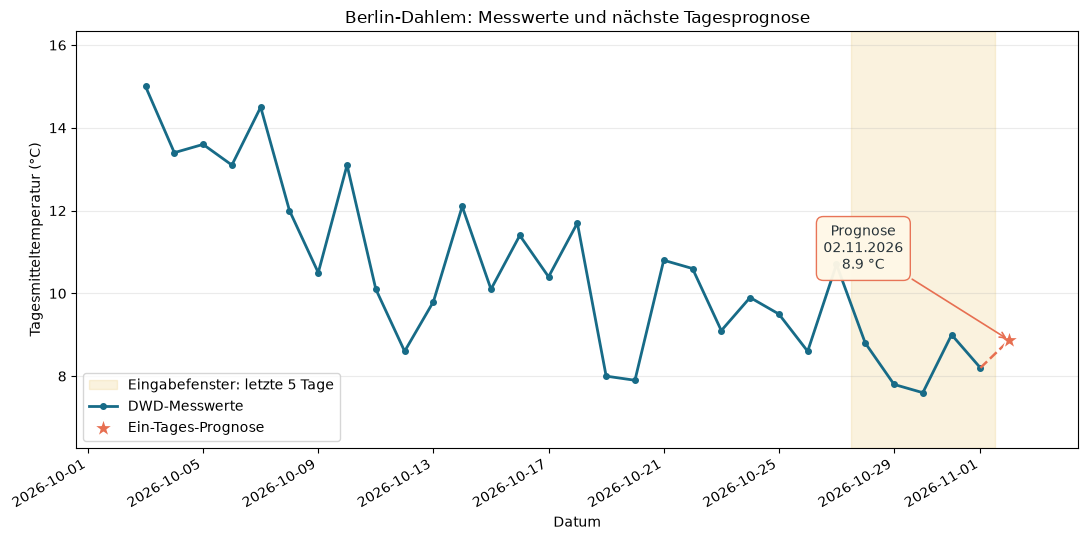

In [8]:
from datetime import timedelta

import matplotlib.pyplot as plt

letzter_messwert_tag = temperaturreihe.last_valid_index()
letzte_fuenf_tage = pd.date_range(end=letzter_messwert_tag, periods=5, freq="D")
letzte_fuenf_werte = temperaturreihe.reindex(letzte_fuenf_tage)
if letzte_fuenf_werte.isna().any():
    raise ValueError("Für die Prognose fehlen zusammenhängende Tageswerte in den letzten fünf Tagen.")

prognose_datum = letzter_messwert_tag + timedelta(days=1)
prognose_tag_im_jahr = tag_im_jahr_1_bis_365(prognose_datum)
if prognose_tag_im_jahr is None:
    raise ValueError("Der 29. Februar ist in diesem einfachen 365-Tage-Modell nicht abgebildet.")

eingaben_naechster_tag = {
    spalte: float(wert)
    for spalte, wert in zip(lag_spalten, letzte_fuenf_werte.to_numpy())
}
eingaben_naechster_tag["tag_im_jahr"] = prognose_tag_im_jahr
X_naechster_tag = pd.DataFrame(
    [eingaben_naechster_tag],
    columns=feature_spalten,
)

# Nach dem Test wird für die reale Prognose mit allen verfügbaren Beispielen trainiert.
modell.fit(trainingsdaten[feature_spalten], trainingsdaten["temp_ziel"])
temperatur_prognose = modell.predict(X_naechster_tag)[0]

print(f"Station: Berlin-Dahlem (FU), 00403")
print(f"Letzter Messwert: {letzter_messwert_tag.date()}")
print(f"Prognosetag: {prognose_datum.date()} (Jahrestag {prognose_tag_im_jahr}/365)")
print(f"Prognostizierte Tagesmitteltemperatur: {temperatur_prognose:.1f} °C")
display(pd.DataFrame([eingaben_naechster_tag | {"temp_prognose_c": temperatur_prognose}]))

plot_start = letzter_messwert_tag - pd.Timedelta(days=29)
letzte_messungen = temperaturreihe.loc[plot_start:letzter_messwert_tag].dropna()
fig, ax = plt.subplots(figsize=(11, 5.5))
ax.axvspan(
    letzte_fuenf_tage[0] - pd.Timedelta(hours=12),
    letzter_messwert_tag + pd.Timedelta(hours=12),
    color="#e9c46a",
    alpha=0.22,
    label="Eingabefenster: letzte 5 Tage",
    zorder=0,
)
ax.plot(
    letzte_messungen.index,
    letzte_messungen.values,
    color="#176b87",
    linewidth=2,
    marker="o",
    markersize=4,
    label="DWD-Messwerte",
    zorder=2,
)
ax.plot(
    [letzter_messwert_tag, prognose_datum],
    [temperaturreihe.loc[letzter_messwert_tag], temperatur_prognose],
    color="#e76f51",
    linewidth=1.8,
    linestyle="--",
    zorder=3,
)
ax.scatter(
    [prognose_datum],
    [temperatur_prognose],
    color="#e76f51",
    edgecolor="white",
    linewidth=1.2,
    marker="*",
    s=220,
    label="Ein-Tages-Prognose",
    zorder=4,
)
ax.annotate(
    f"Prognose\n{prognose_datum:%d.%m.%Y}\n{temperatur_prognose:.1f} °C",
    xy=(prognose_datum, temperatur_prognose),
    xytext=(-105, 48),
    textcoords="offset points",
    ha="center",
    va="bottom",
    fontsize=10,
    color="#263238",
    bbox={"boxstyle": "round,pad=0.5", "facecolor": "#fff8e7", "edgecolor": "#e76f51", "alpha": 0.96},
    arrowprops={"arrowstyle": "->", "color": "#e76f51", "linewidth": 1.2},
    zorder=5,
)
ax.set_title("Berlin-Dahlem: Messwerte und nächste Tagesprognose")
ax.set_ylabel("Tagesmitteltemperatur (°C)")
ax.set_xlabel("Datum")
ax.grid(axis="y", alpha=0.25)
ax.legend(loc="lower left", frameon=True)
ax.margins(x=0.08, y=0.18)
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

## Ergebnis auf einen Blick

### **8,9 °C**

**Prognose für 02.11.2026** · DWD Berlin-Dahlem (FU)

| Testgüte (01.01.2025–01.11.2026) | Random Forest | Baseline „gestern“ |
| --- | ---: | ---: |
| MAE | **1,68 °C** | 1,73 °C |
| RMSE | **2,13 °C** | 2,23 °C |
| R² | **0,920** | – |

Der Vorteil gegenüber der Baseline ist klein. Getestet wurde eine rollierende Ein-Tages-Prognose; das Modell berücksichtigt keine aktuelle Wetterlage und ist keine amtliche Vorhersage.